# Logistic Regression Baseline


In [2]:
import pandas as pd

In [3]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [4]:
import os

print(os.listdir("/content/drive/MyDrive"))

['Classroom', 'Adsız klasör', 'İlke Çerçi Fizik lab 1 (1).gdoc', 'İlke Çerçi Fizik lab 1.docx', 'İlke Çerçi Fizik lab 1.gdoc', 'Bilim Projesi.gslides', 'BMI.gslides', 'ilkeçerçi_231501014_hw2 (1).pdf', 'ilkeçerçi_231501014_hw3.pdf', 'İlke_Çerçi_CENG_231501014 (1).mkv', 'ilkeçerçi_231501014_hw4.pdf', 'Adsız doküman (4).gdoc', 'ing petrol sunumu.gslides', 'LAB_03_Lab3 Prepration Practice Examples.gdoc', 'Rapor (1).gdoc', 'Rapor.gdoc', 'enjoying_with_handicapped_children.gdoc', 'enjoying_with_handicapped_children.pdf', 'Erasmus-Sinavi-Ornegi.docx.pdf', 'Chapter_05.gdoc', 'Hasan Kalyoncu Üniversitesi.pptx', 'EĞİTİM_TEKNOLOJİLERİ_YARIŞMASI_ÖDR_ŞABLONU_TR_mOAlb (1).docx', 'Midterm Equestions for students FE102.gdoc', 'Midterm Equestions for students FE102.pdf', 're&de.pdf', 'PHYS 102 Report Cover Page (4).gdoc', '231501014_ilke_cerci_labReport_1.docx', '231501014_ilke_cerci_labReport_1.pdf', 'cloudComputing.pdf', 'PHYS 102 Report Cover Page (3).gdoc', 'PHYS 102 R

In [5]:
print(os.listdir("/content/drive/MyDrive/crossDomainSentAnlys"))

['old_combined_dataset.csv', 'test_4domain_balanced.csv', 'test_4domain_natural.csv', 'test_with_neutral.csv', 'train_4domain_balanced.csv', 'train_4domain_natural.csv', 'train_with_neutral.csv', 'val_4domain_natural.csv', 'Turkish_movie_sentiment_dataset.csv']


In [6]:
import pandas as pd

train_df = pd.read_csv(
    "/content/drive/MyDrive/crossDomainSentAnlys/train_4domain_natural.csv"
)

test_df = pd.read_csv(
    "/content/drive/MyDrive/crossDomainSentAnlys/test_4domain_natural.csv"
)

In [7]:
train_product = train_df[
    train_df["Domain"] == "Product Reviews"
]

test_product = test_df[
    test_df["Domain"] == "Product Reviews"
]

In [8]:
print(train_product.shape)
print(test_product.shape)

(163874, 4)
(46354, 4)


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2)
)

X_train = vectorizer.fit_transform(train_product["text"])

X_test = vectorizer.transform(test_product["text"])

In [10]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

model.fit(
    X_train,
    train_product["label"]
)

LogisticRegression(max_iter=1000, random_state=42)

In [11]:
y_pred = model.predict(X_test)

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy:",
      accuracy_score(test_product["label"], y_pred))

print("Precision:",
      precision_score(
          test_product["label"],
          y_pred,
          pos_label="Positive"
      ))

print("Recall:",
      recall_score(
          test_product["label"],
          y_pred,
          pos_label="Positive"
      ))

print("Macro-F1:",
      f1_score(
          test_product["label"],
          y_pred,
          average="macro"
      ))

Accuracy: 0.9545023083229063
Precision: 0.9575014387533756
Recall: 0.9956498722581536
Macro-F1: 0.7298355705845594


In [13]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    test_product["label"],
    y_pred
)

print(cm)

[[  987  1920]
 [  189 43258]]


In [14]:
from sklearn.metrics import classification_report

print(
    classification_report(
        test_product["label"],
        y_pred
    )
)

              precision    recall  f1-score   support

    Negative       0.84      0.34      0.48      2907
    Positive       0.96      1.00      0.98     43447

    accuracy                           0.95     46354
   macro avg       0.90      0.67      0.73     46354
weighted avg       0.95      0.95      0.95     46354



In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

def run_in_domain(domain_name):

    train_domain = train_df[
        train_df["Domain"] == domain_name
    ]

    test_domain = test_df[
        test_df["Domain"] == domain_name
    ]

    print(f"\n{'='*60}")
    print(f"Domain: {domain_name}")
    print(f"Train Size: {len(train_domain)}")
    print(f"Test Size: {len(test_domain)}")

    vectorizer = TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2)
    )

    X_train = vectorizer.fit_transform(
        train_domain["text"]
    )

    X_test = vectorizer.transform(
        test_domain["text"]
    )

    model = LogisticRegression(
        random_state=42,
        max_iter=1000
    )

    model.fit(
        X_train,
        train_domain["label"]
    )

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(
        test_domain["label"],
        y_pred
    )

    precision = precision_score(
        test_domain["label"],
        y_pred,
        pos_label="Positive"
    )

    recall = recall_score(
        test_domain["label"],
        y_pred,
        pos_label="Positive"
    )

    macro_f1 = f1_score(
        test_domain["label"],
        y_pred,
        average="macro"
    )

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"Macro-F1: {macro_f1:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            test_domain["label"],
            y_pred
        )
    )

    print("\nConfusion Matrix:")
    print(
        confusion_matrix(
            test_domain["label"],
            y_pred
        )
    )

    return {
        "Domain": domain_name,
        "Train_Size": len(train_domain),
        "Test_Size": len(test_domain),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Macro_F1": macro_f1,
        "y_true": test_domain["label"],
        "y_pred": y_pred
    }

In [22]:
results = []

domains = [
    "Product Reviews",
    "Movie Reviews",
    "Hotel Reviews",
    "Tweets"
]

for domain in domains:
    results.append(
        run_in_domain(domain)
    )


Domain: Product Reviews
Train Size: 163874
Test Size: 46354
Accuracy: 0.9545
Precision: 0.9575
Recall: 0.9956
Macro-F1: 0.7298

Classification Report:
              precision    recall  f1-score   support

    Negative       0.84      0.34      0.48      2907
    Positive       0.96      1.00      0.98     43447

    accuracy                           0.95     46354
   macro avg       0.90      0.67      0.73     46354
weighted avg       0.95      0.95      0.95     46354


Confusion Matrix:
[[  987  1920]
 [  189 43258]]

Domain: Movie Reviews
Train Size: 31363
Test Size: 8871
Accuracy: 0.9161
Precision: 0.9155
Recall: 0.9176
Macro-F1: 0.9161

Classification Report:
              precision    recall  f1-score   support

    Negative       0.92      0.91      0.92      4419
    Positive       0.92      0.92      0.92      4452

    accuracy                           0.92      8871
   macro avg       0.92      0.92      0.92      8871
weighted avg       0.92      0.92      0.92      88

In [17]:
import pandas as pd

results_df = pd.DataFrame(results)

results_df

,Domain,Train_Size,Test_Size,Accuracy,Precision,Recall,Macro_F1
0,Product Reviews,163874,46354,0.954502,0.957501,0.995650,0.729836
1,Movie Reviews,31363,8871,0.916131,0.915509,0.917565,0.916129
2,Hotel Reviews,7668,2169,0.937759,0.952968,0.901483,0.936266
3,Tweets,7737,2189,0.832344,0.810612,0.909091,0.827191


In [23]:
product_result = run_in_domain("Product Reviews")



Domain: Product Reviews
Train Size: 163874
Test Size: 46354
Accuracy: 0.9545
Precision: 0.9575
Recall: 0.9956
Macro-F1: 0.7298

Classification Report:
              precision    recall  f1-score   support

    Negative       0.84      0.34      0.48      2907
    Positive       0.96      1.00      0.98     43447

    accuracy                           0.95     46354
   macro avg       0.90      0.67      0.73     46354
weighted avg       0.95      0.95      0.95     46354


Confusion Matrix:
[[  987  1920]
 [  189 43258]]


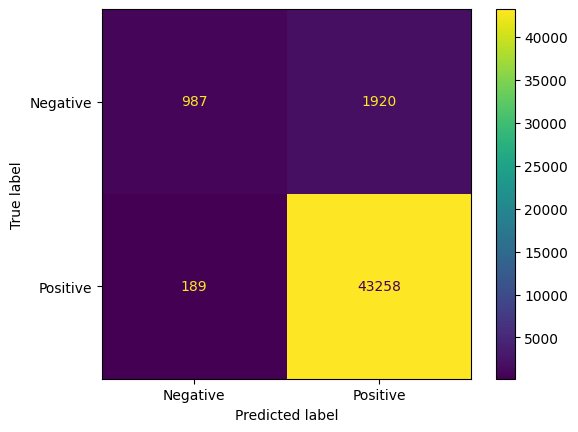

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    product_result["y_true"],
    product_result["y_pred"]
)

In [25]:
movie_result = run_in_domain("Movie Reviews")
hotel_result = run_in_domain("Hotel Reviews")
tweet_result = run_in_domain("Tweets")


Domain: Movie Reviews
Train Size: 31363
Test Size: 8871
Accuracy: 0.9161
Precision: 0.9155
Recall: 0.9176
Macro-F1: 0.9161

Classification Report:
              precision    recall  f1-score   support

    Negative       0.92      0.91      0.92      4419
    Positive       0.92      0.92      0.92      4452

    accuracy                           0.92      8871
   macro avg       0.92      0.92      0.92      8871
weighted avg       0.92      0.92      0.92      8871


Confusion Matrix:
[[4042  377]
 [ 367 4085]]

Domain: Hotel Reviews
Train Size: 7668
Test Size: 2169
Accuracy: 0.9378
Precision: 0.9530
Recall: 0.9015
Macro-F1: 0.9363

Classification Report:
              precision    recall  f1-score   support

    Negative       0.93      0.97      0.95      1225
    Positive       0.95      0.90      0.93       944

    accuracy                           0.94      2169
   macro avg       0.94      0.93      0.94      2169
weighted avg       0.94      0.94      0.94      2169


Conf

<Figure size 500x400 with 0 Axes>

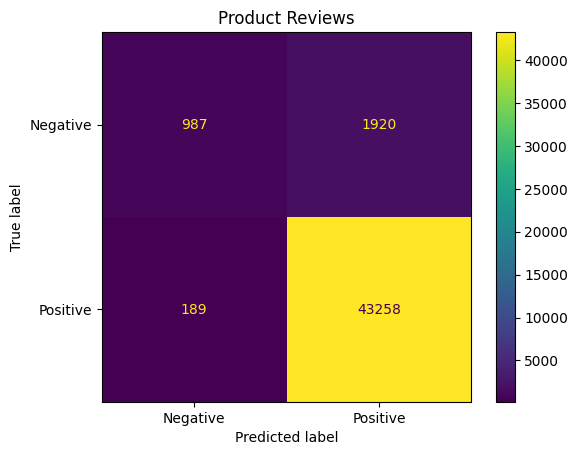

<Figure size 500x400 with 0 Axes>

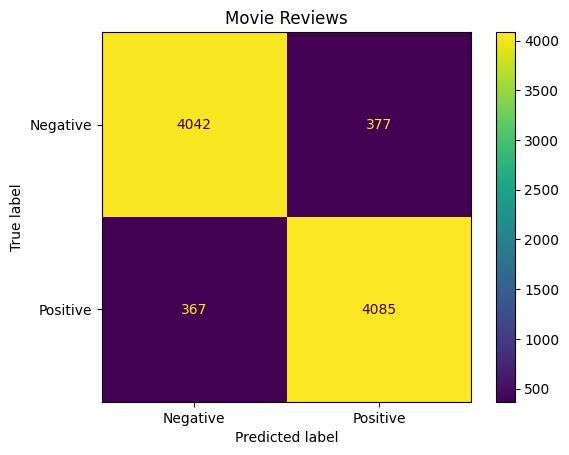

<Figure size 500x400 with 0 Axes>

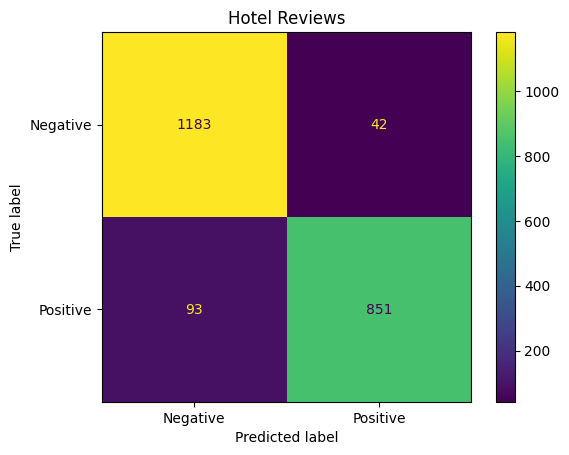

<Figure size 500x400 with 0 Axes>

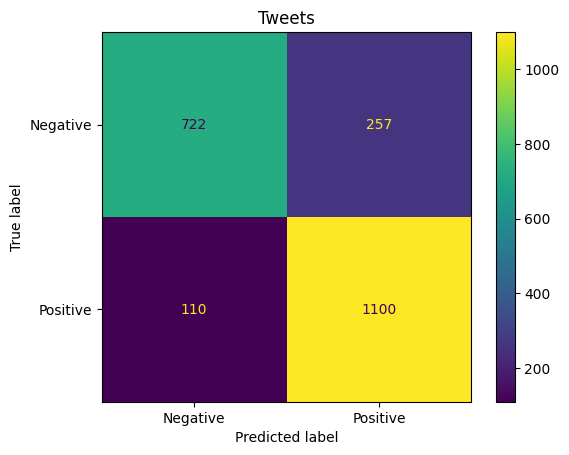

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

results = [
    product_result,
    movie_result,
    hotel_result,
    tweet_result
]

for result in results:

    plt.figure(figsize=(5,4))

    ConfusionMatrixDisplay.from_predictions(
        result["y_true"],
        result["y_pred"]
    )

    plt.title(result["Domain"])

    plt.show()